# Laboratorio OpenDSS & py-dss-interface
## Módulo 2: Extracción Analítica de Datos, Componentes Simétricas y Desbalance (IEC 61000-4-30)

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Extraer masivamente el estado eléctrico de la red en estructuras de datos tabulares (`pandas.DataFrame`).
2. Implementar la transformación de componentes simétricas de **Fortescue** ($V_0, V_+, V_-$) sobre fasores complejos.
3. Evaluar el **Factor de Desbalance de Tensión** ($VUF\%$) según las normas internacionales **IEC 61000-4-30** y **EN 50160**, comparándolo con el índice NEMA (*PVUR*).
4. Analizar la cargabilidad térmica de las líneas frente a límites nominales (`NormAmps`) y de emergencia (`EmerAmps`).
5. Generar visualizaciones profesionales de calidad de potencia y cuellos de botella térmicos.

---
### 1. Marco Matemático: Desbalance de Tensión y Componentes Simétricas

En sistemas polifásicos no simétricos, cualquier conjunto de fasores trifásicos desbalanceados $(\mathbf{V}_A, \mathbf{V}_B, \mathbf{V}_C)$ puede descomponerse en tres sistemas simétricos desacoplados mediante la matriz de transformación de Fortescue $\mathbf{A}$:

$$egin{bmatrix} \mathbf{V}_0 \ \mathbf{V}_+ \ \mathbf{V}_- \end{bmatrix} = rac{1}{3} egin{bmatrix} 1 & 1 & 1 \ 1 & a & a^2 \ 1 & a^2 & a \end{bmatrix} egin{bmatrix} \mathbf{V}_A \ \mathbf{V}_B \ \mathbf{V}_C \end{bmatrix}$$

Donde $a = e^{j rac{2\pi}{3}} = -rac{1}{2} + j rac{\sqrt{3}}{2} = 1ngle 120^\circ$.

* $\mathbf{V}_0$: Componente de Secuencia Cero (Homopolar).
* $\mathbf{V}_+$: Componente de Secuencia Positiva (Secuencia directa, genera par electromagnético útil en motores).
* $\mathbf{V}_-$: Componente de Secuencia Negativa (Secuencia inversa, induce campos rotativos contrarios provocando calentamiento severo y frenado en máquinas eléctricas).

**Definición IEC 61000-4-30 y EN 50160 (True VUF):**
$$VUF\% = rac{|\mathbf{V}_-|}{|\mathbf{V}_+|} 	imes 100\%$$

*Límite Regulatorio:* El estándar IEC establece que el $VUF\%$ en redes de distribución pública no debe superar el **$2.0\%$** (con un límite excepcional del $3.0\%$ en zonas con alta penetración de tracción monofásica o ramales rurales extensos).


In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

# Importar funciones analíticas del laboratorio
sys.path.append(os.getcwd())
from utils.lab_dss_toolkit import (
    get_network_snapshot,
    calculate_vuf_iec,
    calculate_branch_loading,
    plot_voltage_profile,
    plot_unbalance_summary
)

# Inicializar motor y cargar circuito
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False
circuit_path = os.path.join(base_dir, "data", "circuit_lab_bt", "Master_LabBT.dss")
dss.text(f"compile '{circuit_path}'")
dss.solution.solve()

print("[OK] Circuito cargado y resuelto exitosamente.")


[OK] Circuito cargado y resuelto exitosamente.


---
### 2. Extracción Estructurada con el Toolkit del Laboratorio

Utilizamos `get_network_snapshot(dss)` para generar de manera automática un reporte completo en DataFrames.


In [2]:
# Extraer snapshot consolidado
snapshot = get_network_snapshot(dss)

df_buses = snapshot["buses"]
df_lines = snapshot["lines"]
df_loads = snapshot["loads"]
df_summary = snapshot["summary"]

print("=== RESUMEN OPERATIVO GLOBAL ===")
print(df_summary.to_string(index=False))


=== RESUMEN OPERATIVO GLOBAL ===
 Total_Generation_kW  Total_Generation_kvar  Total_Losses_kW  Total_Losses_kvar  Losses_Percentage  Circuit_Converged
           64.486241              25.173817         2.488406           1.734619           3.858817               True


---
### 3. Evaluación Detallada del Desbalance de Tensión (VUF%)

Examinemos los valores de tensión por fase y el factor $VUF\%$ calculado en cada barra trifásica de la red:


=== FACTORES DE DESBALANCE NODALES ===
          Bus    Va_pu    Vb_pu    Vc_pu  VUF_percent  NEMA_PVUR_pct
    sourcebus 0.999978 0.999977 0.999986     0.000567          0.001
substation_bt 0.990020 0.986894 0.992976     0.286591          0.310
       node_1 0.979476 0.969124 0.986976     0.431169          0.961
       node_2 0.972368 0.963446 0.979301     0.417244          0.850
       node_3 0.966288 0.965998 0.976832     0.338504          0.735
       node_4 0.968118 0.959884 0.970421     0.359786          0.648
       node_5 0.962516 0.963315 0.963274     0.186065          0.054
       node_6 0.984819 0.953959 0.987947     0.742894          2.216


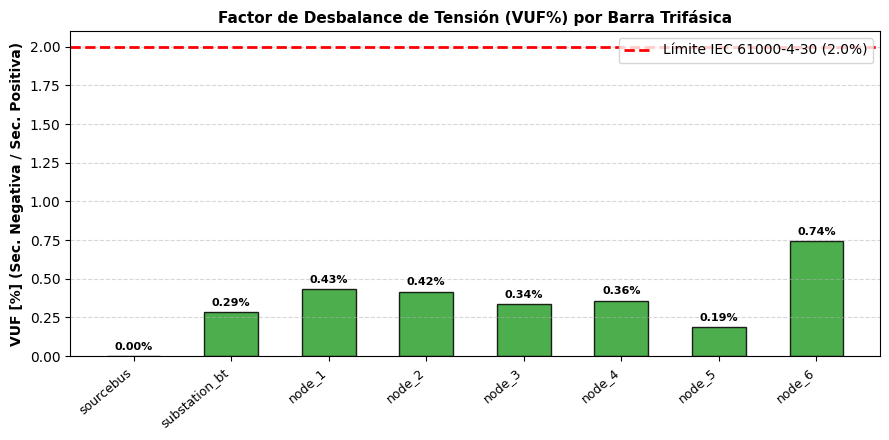

In [3]:
# Filtrar únicamente barras trifásicas
df_vuf = df_buses.dropna(subset=["VUF_percent"])[["Bus", "Va_pu", "Vb_pu", "Vc_pu", "VUF_percent"]].copy()

# Comparación con el índice NEMA PVUR
# PVUR% = max(|Vi - Vavg|) / Vavg * 100
pvur_list = []
for idx, row in df_vuf.iterrows():
    vals = np.array([row["Va_pu"], row["Vb_pu"], row["Vc_pu"]])
    v_avg = np.mean(vals)
    pvur = np.max(np.abs(vals - v_avg)) / v_avg * 100.0
    pvur_list.append(round(pvur, 3))
df_vuf["NEMA_PVUR_pct"] = pvur_list

print("=== FACTORES DE DESBALANCE NODALES ===")
print(df_vuf.to_string(index=False))

# Visualizar gráfico de barras frente al límite regulatorio IEC
fig_vuf = plot_unbalance_summary(df_buses, limit_vuf=2.0)
plt.show()


---
### 4. Evaluación de Capacidad Térmica de Conductores (Ampacity)

La corriente admisible en régimen permanente (`NormAmps`) no debe superarse para evitar degradación acelerada del aislamiento térmico del cable (polietileno reticulado XLPE a $90^\circ	ext{C}$).


=== ESTADO TÉRMICO DE CONDUCTORES Y ACOMETIDAS ===
       Line  Phases  Length_m  I_max_A  NormAmps_A  Loading_pct Status
    drop_l8       1      30.0    54.73        90.0        60.81 NORMAL
    drop_l3       1      18.0    45.00        90.0        50.00 NORMAL
    drop_l6       1      22.0    39.99        90.0        44.43 NORMAL
    drop_l2       1      20.0    39.24        90.0        43.60 NORMAL
line_sub_n1       3     120.0   121.57       305.0        39.86 NORMAL
    drop_l4       1      25.0    33.51        90.0        37.23 NORMAL
    drop_l1       1      15.0    30.32        90.0        33.69 NORMAL
    drop_l7       1      16.0    28.78        90.0        31.98 NORMAL
    drop_l5       1      15.0    27.62        90.0        30.69 NORMAL
 line_n1_n6       3      85.0    54.73       190.0        28.81 NORMAL
 line_n1_n2       3     100.0    73.78       305.0        24.19 NORMAL
 line_n2_n4       3      90.0    39.99       190.0        21.05 NORMAL
 line_n4_n5       3      7

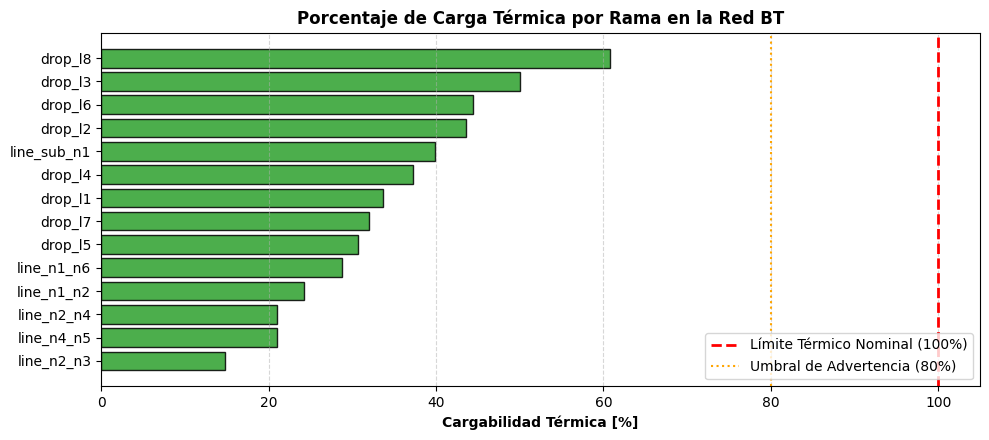

In [4]:
# Análisis de carga térmica de ramas
df_termico = df_lines.sort_values(by="Loading_pct", ascending=False)

print("=== ESTADO TÉRMICO DE CONDUCTORES Y ACOMETIDAS ===")
print(df_termico[["Line", "Phases", "Length_m", "I_max_A", "NormAmps_A", "Loading_pct", "Status"]].to_string(index=False))

# Gráfica de barras de cargabilidad
plt.figure(figsize=(10, 4.5), dpi=100)
colores = ['#2ca02c' if x <= 80 else ('#ff7f0e' if x <= 100 else '#d62728') for x in df_termico['Loading_pct']]
plt.barh(df_termico['Line'], df_termico['Loading_pct'], color=colores, edgecolor='black', alpha=0.85)
plt.axvline(100, color='red', linestyle='--', linewidth=2, label='Límite Térmico Nominal (100%)')
plt.axvline(80, color='orange', linestyle=':', linewidth=1.5, label='Umbral de Advertencia (80%)')
plt.xlabel("Cargabilidad Térmica [%]", fontweight='bold')
plt.title("Porcentaje de Carga Térmica por Rama en la Red BT", fontweight='bold')
plt.legend(loc='lower right')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
### 5. Ejercicio Guiado: Simulación de Evento Crítico de Desbalance

**Escenario:**
Supongamos que un usuario comercial no autorizado conecta un taller de soldadura monofásica de alta potencia en la barra `LoadBus_8` (Fase B), incrementando la demanda de `Load_8` a $28.0	ext{ kW}$ (Factor de potencia 0.85).

**Consignas:**
1. Configure la nueva potencia de `Load_8` (`kw=28.0`, `pf=0.85`).
2. Resuelva el flujo de potencia y verifique:
   * ¿Qué barras superan el límite regulatorio IEC de $VUF > 2.0\%$?
   * ¿Cuál es el nuevo nivel de cargabilidad de la acometida `Drop_L8` y de la línea `Line_N1_N6`?
   * ¿Se viola el límite de tensión mínima ($V_{	ext{min}} < 0.90	ext{ pu}$)?


=== RESULTADOS DEL EVENTO CRÍTICO ===
Barras con desbalance excesivo (VUF > 2.0%): 1
   Bus  VUF_percent    Va_pu    Vb_pu    Vc_pu
node_6     2.281284 1.008211 0.888117 0.986966

Ramas con advertencia o sobrecarga térmica (> 80%):
      Line  I_max_A  NormAmps_A  Loading_pct     Status
line_n1_n6   164.84       190.0        86.76     ALERTA
   drop_l8   164.84        90.0       183.16 SOBRECARGA

Tensión mínima absoluta registrada en la red: 0.8652 pu
[OK] Red restaurada a condiciones nominales.


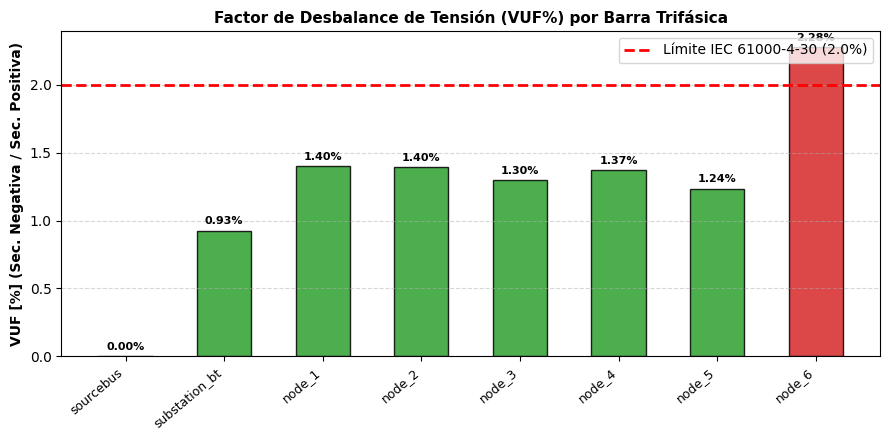

In [5]:
# 1. Modificar carga 8
dss.loads.name = "load_8"
dss.loads.kw = 28.0
dss.loads.pf = 0.85
dss.solution.solve()

# 2. Extraer snapshot post-contingencia
snap_crit = get_network_snapshot(dss)
df_buses_crit = snap_crit["buses"]
df_lines_crit = snap_crit["lines"]

# 3. Evaluar superación de límites
barras_violan_vuf = df_buses_crit[df_buses_crit["VUF_percent"] > 2.0][["Bus", "VUF_percent", "Va_pu", "Vb_pu", "Vc_pu"]]
lineas_sobrecargadas = df_lines_crit[df_lines_crit["Loading_pct"] > 80.0][["Line", "I_max_A", "NormAmps_A", "Loading_pct", "Status"]]

print("=== RESULTADOS DEL EVENTO CRÍTICO ===")
print(f"Barras con desbalance excesivo (VUF > 2.0%): {len(barras_violan_vuf)}")
if not barras_violan_vuf.empty:
    print(barras_violan_vuf.to_string(index=False))

print(f"\nRamas con advertencia o sobrecarga térmica (> 80%):")
print(lineas_sobrecargadas.to_string(index=False))

print(f"\nTensión mínima absoluta registrada en la red: {df_buses_crit['V_min_pu'].min():.4f} pu")

# Visualizar el nuevo desbalance
fig_crit_vuf = plot_unbalance_summary(df_buses_crit, limit_vuf=2.0)
plt.show()

# Restaurar carga original
dss.loads.kw = 11.0
dss.loads.pf = 0.92
dss.solution.solve()
print("[OK] Red restaurada a condiciones nominales.")


---
### Conclusiones del Módulo 2
1. La formulación matemática de Fortescue permite cuantificar la severidad del desbalance mediante la componente de secuencia negativa ($V_-$), responsable directa del sobrecalentamiento de motores y transformadores.
2. Cargas monofásicas asimétricas de gran porte pueden disparar el $VUF\%$ local muy por encima del límite regulatorio del $2\%$, provocando también caídas de tensión inaceptables en fases adyacentes.
3. La combinación de DataFrames y el toolkit analítico automatiza la auditoría de redes para distribuidoras eléctricas y estudios de conexión.
